In [1]:
pip install iTransformer optuna pandas numpy scikit-learn torch matplotlib

Note: you may need to restart the kernel to use updated packages.
Note: you may need to restart the kernel to use updated packages.


In [2]:
# Import shared modules
import sys
sys.path.append('.')

from data_loader import load_btc_data, load_sentiment_data, process_sentiment_hourly, merge_dataframes, create_hourly_data, create_validation_periods, create_sequences
from model_utils import load_model, make_predictions, prepare_tensor
from backtest_functions import backtest_profit_threshold_with_trades, backtest_profit_threshold, backtest_ts_momentum
from utils import cv_optimize_threshold_parameters, cv_optimize_risk_parameters, cv_optimize_momentum_parameters, plot_trades, save_trades_to_csv, create_trades_dataframe

# Force reload modules
import importlib
import data_loader
importlib.reload(data_loader)
import utils
importlib.reload(utils)
from data_loader import create_validation_periods
from utils import cv_optimize_threshold_parameters

# Explicitly reload the optimization function
importlib.reload(utils)
from utils import cv_optimize_threshold_parameters

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

/home/kosmo/Documents/Magis-files/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [3]:
path = "./data/"

In [4]:
# Load sentiment-only data
print("Loading BTC data...")
df = load_btc_data(path)

print("Loading sentiment data...")
df_sentiments = load_sentiment_data(path)

print("Processing sentiment data...")
df_hourly_sentiments = process_sentiment_hourly(df_sentiments)

print("Merging data...")
merged_df = merge_dataframes(df, df_hourly_sentiments)

print("Creating hourly data...")
features = ['price_change_1h', 'close', 'usd_volume_buy', 'usd_volume_sell', 'predicted_sentiment_24h_avg', 'predicted_sentiment_4h_decay']
df_hourly = create_hourly_data(merged_df, features)

print(f"Data shape: {df_hourly.shape}")
df_hourly.head()

Loading BTC data...
Loading sentiment data...
Processing sentiment data...
Loading sentiment data...
Processing sentiment data...
Merging data...
Merging data...
Creating hourly data...
Creating hourly data...
Data shape: (59815, 6)
Data shape: (59815, 6)


,price_change_1h,close,usd_volume_buy,usd_volume_sell,predicted_sentiment_24h_avg,predicted_sentiment_4h_decay
datetime,,,,,,
2019-01-03 09:00:00+00:00,0.81,3805.81,3.135872e+06,6.326423e+06,0.0,0.0
2019-01-03 10:00:00+00:00,5.71,3811.52,2.273019e+06,5.029916e+06,0.0,0.0
2019-01-03 11:00:00+00:00,-7.52,3804.00,3.248480e+06,6.265895e+06,0.0,0.0
2019-01-03 12:00:00+00:00,14.02,3818.02,2.567056e+06,4.734821e+06,0.0,0.0
2019-01-03 13:00:00+00:00,-0.66,3817.36,2.129562e+06,4.186558e+06,0.0,0.0


In [5]:
# Create validation periods
train_df, val_df_period1, val_df_period2 = create_validation_periods(df_hourly)

print(f"Training data: {len(train_df)} samples")
print(f"Period 1 validation: {len(val_df_period1)} samples")
print(f"Period 2 validation: {len(val_df_period2)} samples")

# Create sequences
seq_length = 24*7  # 7 days
X_val_period1, y_val_period1 = create_sequences(val_df_period1, 'price_change_1h', seq_length)
X_val_period2, y_val_period2 = create_sequences(val_df_period2, 'price_change_1h', seq_length)

print(f"Period 1 - X shape: {X_val_period1.shape}, y shape: {y_val_period1.shape}")

# Use period 1 for initial testing
X_val, y_val = X_val_period1, y_val_period1

Training data: 47346 samples
Period 1 validation: 4392 samples
Period 2 validation: 4344 samples
Period 1 - X shape: (4224, 168, 5), y shape: (4224,)


In [6]:
# Load sentiment-only model (5 input features, excluding target)
model_path = 'dim-64_depth-2_heads-16_dim_head-32_lr-0.007328042029112791'  # Sentiment-only model
model, device = load_model(model_path, num_variates=5, lookback_len=24*7, dim=64, depth=2, heads=16, dim_head=32)

# Prepare data
X_val_tensor = prepare_tensor(X_val, device)

# Make predictions
val_pred_1h_change = make_predictions(model, X_val_tensor, device, df_hourly.columns.get_loc('price_change_1h'))

# Get close prices for backtesting
close_price = val_df_period1['close'][seq_length:].values

print(f"Predictions shape: {val_pred_1h_change.shape}")
print(f"Close price shape: {close_price.shape}")

Non-A100 GPU detected, using math or mem efficient attention if input tensor is on cuda
Predictions shape: (4224,)
Close price shape: (4224,)
Predictions shape: (4224,)
Close price shape: (4224,)


Performing CV optimization on training data...
CV optimizing threshold parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10...


[I 2025-12-09 21:07:54,590] A new study created in memory with name: no-name-f7e7799a-0cf8-4226-8c55-7ffeb7619969
[I 2025-12-09 21:07:54,641] Trial 1 finished with value: 1.6056260922883843 and parameters: {'threshold': 1.4236697750019989, 'hold_hours': 165}. Best is trial 1 with value: 1.6056260922883843.
[I 2025-12-09 21:07:54,641] Trial 1 finished with value: 1.6056260922883843 and parameters: {'threshold': 1.4236697750019989, 'hold_hours': 165}. Best is trial 1 with value: 1.6056260922883843.
[I 2025-12-09 21:07:54,653] Trial 0 finished with value: 2.1718662751783033 and parameters: {'threshold': 0.0372774884995, 'hold_hours': 74}. Best is trial 0 with value: 2.1718662751783033.
[I 2025-12-09 21:07:54,653] Trial 0 finished with value: 2.1718662751783033 and parameters: {'threshold': 0.0372774884995, 'hold_hours': 74}. Best is trial 0 with value: 2.1718662751783033.
[I 2025-12-09 21:07:54,664] Trial 2 finished with value: 1.4101719929576653 and parameters: {'threshold': 1.0025281266

Fold 1 - Best threshold: 0.21%, Hold hours: 92, Sharpe: 2.88
Processing CV fold 2/10...


[I 2025-12-09 21:07:59,008] A new study created in memory with name: no-name-aabbbb97-f358-4b68-88c1-b32357bf70bb
[I 2025-12-09 21:07:59,029] Trial 0 finished with value: 0.0836436400548455 and parameters: {'threshold': 1.0679239473186437, 'hold_hours': 63}. Best is trial 0 with value: 0.0836436400548455.
[I 2025-12-09 21:07:59,029] Trial 0 finished with value: 0.0836436400548455 and parameters: {'threshold': 1.0679239473186437, 'hold_hours': 63}. Best is trial 0 with value: 0.0836436400548455.
[I 2025-12-09 21:07:59,048] Trial 1 finished with value: 0.8332097878167241 and parameters: {'threshold': 1.8418689930163656, 'hold_hours': 102}. Best is trial 1 with value: 0.8332097878167241.
[I 2025-12-09 21:07:59,048] Trial 1 finished with value: 0.8332097878167241 and parameters: {'threshold': 1.8418689930163656, 'hold_hours': 102}. Best is trial 1 with value: 0.8332097878167241.
[I 2025-12-09 21:07:59,060] Trial 2 finished with value: -0.0603050679503316 and parameters: {'threshold': 0.520

Fold 2 - Best threshold: 1.88%, Hold hours: 54, Sharpe: 1.23
Processing CV fold 3/10...


[I 2025-12-09 21:08:03,263] A new study created in memory with name: no-name-56c172a5-6ca9-454d-859e-73e7c012feef
[I 2025-12-09 21:08:03,285] Trial 0 finished with value: -0.3970133097416096 and parameters: {'threshold': 1.6688998341967436, 'hold_hours': 132}. Best is trial 0 with value: -0.3970133097416096.
[I 2025-12-09 21:08:03,335] Trial 2 finished with value: -0.3036623987988336 and parameters: {'threshold': 0.5683835405375711, 'hold_hours': 68}. Best is trial 2 with value: -0.3036623987988336.
[I 2025-12-09 21:08:03,285] Trial 0 finished with value: -0.3970133097416096 and parameters: {'threshold': 1.6688998341967436, 'hold_hours': 132}. Best is trial 0 with value: -0.3970133097416096.
[I 2025-12-09 21:08:03,335] Trial 2 finished with value: -0.3036623987988336 and parameters: {'threshold': 0.5683835405375711, 'hold_hours': 68}. Best is trial 2 with value: -0.3036623987988336.
[I 2025-12-09 21:08:03,355] Trial 6 finished with value: -0.5785235298693643 and parameters: {'threshold

... (11 outputs left out)

[I 2025-12-09 21:08:29,128] A new study created in memory with name: no-name-8a8da9fa-248f-47e1-871e-45d05091950b
[I 2025-12-09 21:08:29,147] Trial 0 finished with value: 1.5047852522634138 and parameters: {'threshold': 0.8905246061120404, 'hold_hours': 123}. Best is trial 0 with value: 1.5047852522634138.
[I 2025-12-09 21:08:29,161] Trial 1 finished with value: 1.517043892847893 and parameters: {'threshold': 1.209263933143784, 'hold_hours': 133}. Best is trial 1 with value: 1.517043892847893.
[I 2025-12-09 21:08:29,171] Trial 2 finished with value: 1.5465960618884276 and parameters: {'threshold': 0.4247741206129483, 'hold_hours': 99}. Best is trial 2 with value: 1.5465960618884276.
[I 2025-12-09 21:08:29,147] Trial 0 finished with value: 1.5047852522634138 and parameters: {'threshold': 0.8905246061120404, 'hold_hours': 123}. Best is trial 0 with value: 1.5047852522634138.
[I 2025-12-09 21:08:29,161] Trial 1 finished with value: 1.517043892847893 and parameters: {'threshold': 1.2092639

Fold 9 - Best threshold: 1.34%, Hold hours: 79, Sharpe: 2.22
Processing CV fold 10/10...


[I 2025-12-09 21:08:33,506] A new study created in memory with name: no-name-9a76e624-9846-48b3-a5d4-3e331261f162
[I 2025-12-09 21:08:33,532] Trial 0 finished with value: 1.7744997733210341 and parameters: {'threshold': 0.10225465580223349, 'hold_hours': 161}. Best is trial 0 with value: 1.7744997733210341.
[I 2025-12-09 21:08:33,540] Trial 1 finished with value: 1.4503617274402822 and parameters: {'threshold': 0.63291117016302, 'hold_hours': 7}. Best is trial 0 with value: 1.7744997733210341.
[I 2025-12-09 21:08:33,549] Trial 2 finished with value: 2.274135106202048 and parameters: {'threshold': 1.2272383593323568, 'hold_hours': 159}. Best is trial 2 with value: 2.274135106202048.
[I 2025-12-09 21:08:33,532] Trial 0 finished with value: 1.7744997733210341 and parameters: {'threshold': 0.10225465580223349, 'hold_hours': 161}. Best is trial 0 with value: 1.7744997733210341.
[I 2025-12-09 21:08:33,540] Trial 1 finished with value: 1.4503617274402822 and parameters: {'threshold': 0.632911

Fold 10 - Best threshold: 1.19%, Hold hours: 19, Sharpe: 2.84
CV Best threshold: 1.33%, Hold hours: 73, Average Sharpe ratio: 1.22

Optimized parameters:
Threshold: 1.33%
Hold Hours: 73

BACKTESTING ON TEST DATA

--- Test Period 1 ---
Backtest trades saved to backtest_results/sentiment_only/threshold_backtest_trades-1.csv (159 trades)


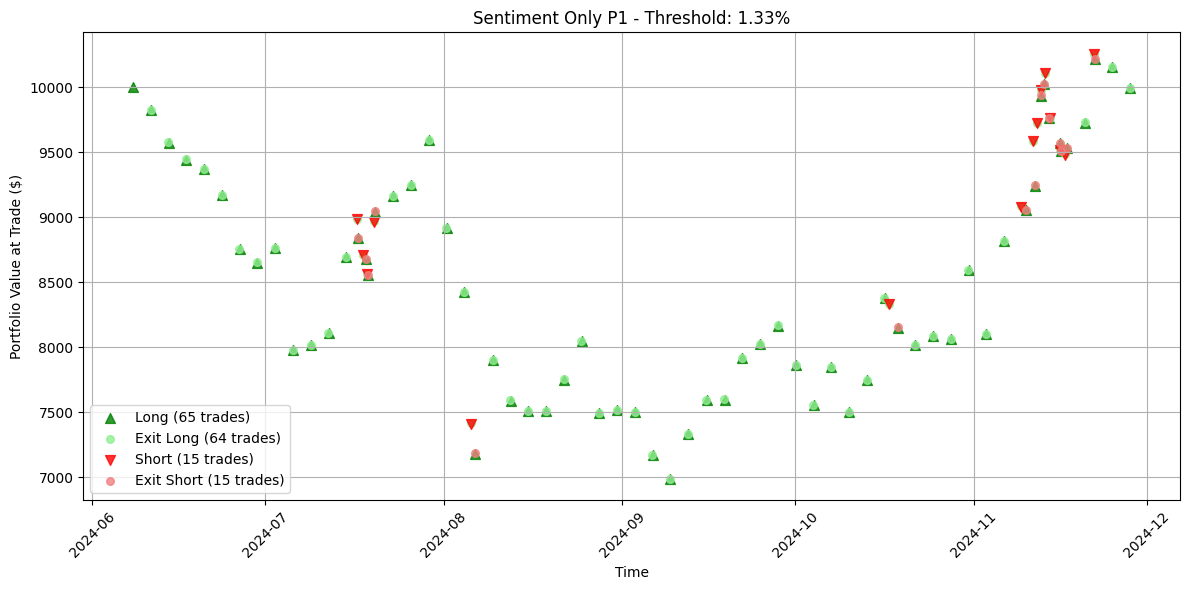


--- Test Period 2 ---
Backtest trades saved to backtest_results/sentiment_only/threshold_backtest_trades-2.csv (153 trades)


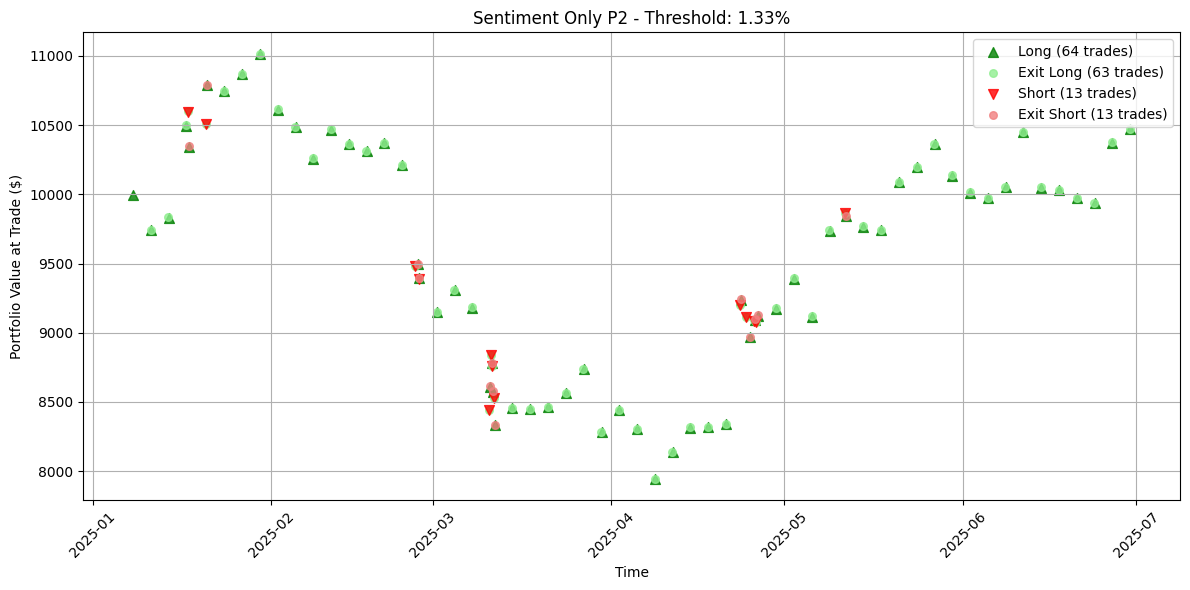

In [7]:
# CV Optimization and Backtesting on Test Data
initial_capital = 10000
fixed_transaction_cost_pct = 0.0275
seq_length = 24*7  # 7 days

print("Performing CV optimization on training data...")

# CV optimize threshold parameters
print("CV optimizing threshold parameters...")
# Load CPU model for CV
cv_model, cv_device = load_model(model_path, num_variates=5, lookback_len=24*7, dim=64, depth=2, heads=16, dim_head=32, device='cpu')
best_threshold, best_hold_hours = cv_optimize_threshold_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=False
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

# Now backtest on test periods with optimized parameters
print("\n" + "="*50)
print("BACKTESTING ON TEST DATA")
print("="*50)

# Test Period 1 Backtests
print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Threshold backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Threshold Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/sentiment_only/threshold_backtest_trades-1.csv')
plot_trades(trades_df, f'Sentiment Only P1 - Threshold: {best_threshold:.2f}%')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Threshold backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold_with_trades(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, fixed_transaction_cost_pct, best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Threshold Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/sentiment_only/threshold_backtest_trades-2.csv')
plot_trades(trades_df, f'Sentiment Only P2 - Threshold: {best_threshold:.2f}%')

CV optimizing risk parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for risk optimization...


[I 2025-12-09 21:08:38,608] A new study created in memory with name: no-name-88e42ee0-db85-46be-9f7e-3a984269b953
[I 2025-12-09 21:08:38,640] Trial 1 finished with value: 3.3151496866639363 and parameters: {'threshold': 0.36849722441090554, 'target_risk': 0.17821849573255663, 'hold_hours': 67}. Best is trial 1 with value: 3.3151496866639363.
[I 2025-12-09 21:08:38,640] Trial 0 finished with value: 2.637455033431704 and parameters: {'threshold': 0.46713717140351346, 'target_risk': 2.3492625008728227, 'hold_hours': 56}. Best is trial 1 with value: 3.3151496866639363.
[I 2025-12-09 21:08:38,688] Trial 5 finished with value: 1.8528211755136674 and parameters: {'threshold': 1.24539393680886, 'target_risk': 1.9075010765843445, 'hold_hours': 110}. Best is trial 1 with value: 3.3151496866639363.
[I 2025-12-09 21:08:38,690] Trial 3 finished with value: 2.066115556169996 and parameters: {'threshold': 1.1246814601790813, 'target_risk': 1.0558662043910807, 'hold_hours': 128}. Best is trial 1 with 

Fold 1 - Best threshold: 0.41%, Risk: 0.26%, Hold hours: 56, Sharpe: 3.74
Processing CV fold 2/10 for risk optimization...


[I 2025-12-09 21:08:50,179] A new study created in memory with name: no-name-17254377-5a13-441e-958d-fe1ff79790e2
[I 2025-12-09 21:08:50,210] Trial 1 finished with value: 0.33852639330627116 and parameters: {'threshold': 0.4847202550228528, 'target_risk': 0.7331137316411263, 'hold_hours': 64}. Best is trial 1 with value: 0.33852639330627116.
[I 2025-12-09 21:08:50,214] Trial 0 finished with value: 0.7890916143220691 and parameters: {'threshold': 1.3962170010299437, 'target_risk': 0.5084626714211421, 'hold_hours': 92}. Best is trial 0 with value: 0.7890916143220691.
[I 2025-12-09 21:08:50,251] Trial 2 finished with value: 0.7858913370521003 and parameters: {'threshold': 1.9112106907273285, 'target_risk': 0.09166026637530655, 'hold_hours': 164}. Best is trial 0 with value: 0.7890916143220691.
[I 2025-12-09 21:08:50,284] Trial 4 finished with value: 1.0194594002323467 and parameters: {'threshold': 1.8556812833168785, 'target_risk': 0.2722472790024479, 'hold_hours': 115}. Best is trial 4 w

Fold 2 - Best threshold: 1.89%, Risk: 0.18%, Hold hours: 84, Sharpe: 1.40
Processing CV fold 3/10 for risk optimization...


[I 2025-12-09 21:09:01,285] A new study created in memory with name: no-name-3561b89c-f132-45e2-9d96-0c59aca68a0a
[I 2025-12-09 21:09:01,314] Trial 1 finished with value: -0.4501888725614107 and parameters: {'threshold': 0.6505008256793862, 'target_risk': 1.2565337053690668, 'hold_hours': 44}. Best is trial 1 with value: -0.4501888725614107.
[I 2025-12-09 21:09:01,320] Trial 0 finished with value: -0.6469697608466508 and parameters: {'threshold': 0.9347327189323483, 'target_risk': 1.079834456686315, 'hold_hours': 76}. Best is trial 1 with value: -0.4501888725614107.
[I 2025-12-09 21:09:01,342] Trial 2 finished with value: -0.2789270114390585 and parameters: {'threshold': 1.7181328508878266, 'target_risk': 2.2866091321738176, 'hold_hours': 48}. Best is trial 2 with value: -0.2789270114390585.
[I 2025-12-09 21:09:01,358] Trial 3 finished with value: -0.2809281998607021 and parameters: {'threshold': 0.913775354853967, 'target_risk': 0.34124618461443174, 'hold_hours': 139}. Best is trial 2

... (11 outputs left out)

[I 2025-12-09 21:10:08,895] A new study created in memory with name: no-name-2ded2818-4604-4965-9132-fb77e3ba50ad
[I 2025-12-09 21:10:08,930] Trial 0 finished with value: 1.383416133811341 and parameters: {'threshold': 1.7945627992905622, 'target_risk': 0.03737921380620318, 'hold_hours': 56}. Best is trial 0 with value: 1.383416133811341.
[I 2025-12-09 21:10:08,949] Trial 1 finished with value: 1.4511841534796157 and parameters: {'threshold': 0.845911519098529, 'target_risk': 1.2248627548164503, 'hold_hours': 22}. Best is trial 1 with value: 1.4511841534796157.
[I 2025-12-09 21:10:08,953] Trial 3 finished with value: 1.625003129372535 and parameters: {'threshold': 0.5474949427787354, 'target_risk': 0.20397941654740545, 'hold_hours': 168}. Best is trial 3 with value: 1.625003129372535.
[I 2025-12-09 21:10:08,957] Trial 2 finished with value: 1.500981535503262 and parameters: {'threshold': 0.5860711111047888, 'target_risk': 0.9501302746373095, 'hold_hours': 149}. Best is trial 3 with val

Fold 9 - Best threshold: 1.34%, Risk: 0.46%, Hold hours: 153, Sharpe: 2.51
Processing CV fold 10/10 for risk optimization...


[I 2025-12-09 21:10:19,711] A new study created in memory with name: no-name-76af0c9d-296f-4940-be7a-d7c0af125286
[I 2025-12-09 21:10:19,739] Trial 1 finished with value: 1.6715455000916428 and parameters: {'threshold': 1.507196462704937, 'target_risk': 0.8112178240036184, 'hold_hours': 47}. Best is trial 1 with value: 1.6715455000916428.
[I 2025-12-09 21:10:19,743] Trial 0 finished with value: 1.9024037473407471 and parameters: {'threshold': 1.060316642788302, 'target_risk': 0.09759615806412669, 'hold_hours': 136}. Best is trial 0 with value: 1.9024037473407471.
[I 2025-12-09 21:10:19,784] Trial 3 finished with value: 1.8148582661562909 and parameters: {'threshold': 1.7300708794084334, 'target_risk': 1.114161142128464, 'hold_hours': 140}. Best is trial 0 with value: 1.9024037473407471.
[I 2025-12-09 21:10:19,784] Trial 2 finished with value: 2.5209966651125217 and parameters: {'threshold': 1.2933129244610104, 'target_risk': 1.1537122675329667, 'hold_hours': 46}. Best is trial 2 with v

Fold 10 - Best threshold: 1.92%, Risk: 2.48%, Hold hours: 11, Sharpe: 3.07
CV Optimal threshold: 1.46%, Risk: 0.79%, Hold hours: 65, Average Sharpe: 1.71

Optimized parameters:
Threshold: 1.46%
Target Risk: 0.79%
Hold Hours: 65

--- Test Period 1 ---
Backtest trades saved to backtest_results/sentiment_only/risk_based_backtest_trades-1.csv (167 trades)


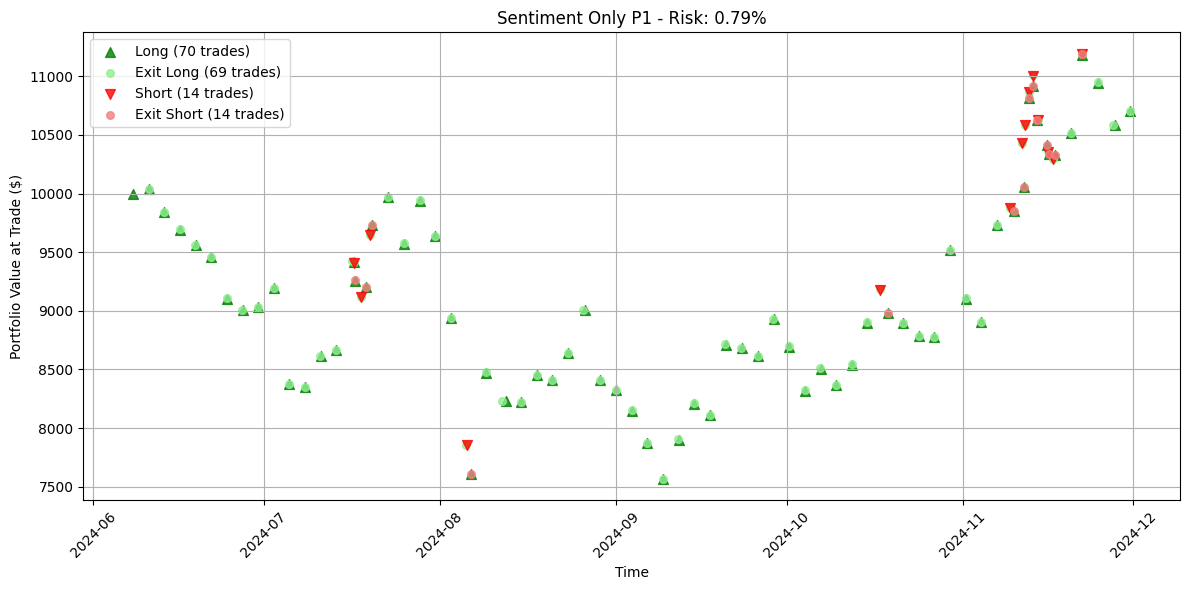


--- Test Period 2 ---
Backtest trades saved to backtest_results/sentiment_only/risk_based_backtest_trades-2.csv (161 trades)


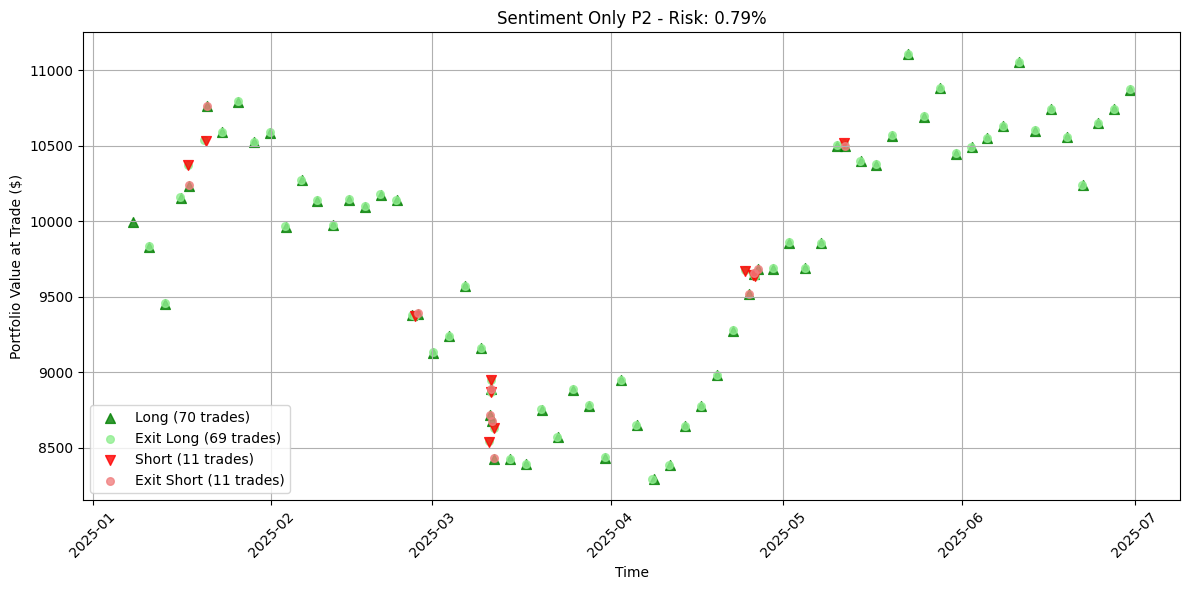

In [8]:
# CV optimize risk parameters
print("CV optimizing risk parameters...")
best_threshold, best_target_risk, best_hold_hours = cv_optimize_risk_parameters(
    train_df, cv_model, cv_device, seq_length, 'price_change_1h', initial_capital, fixed_transaction_cost_pct, include_target=False
)

print(f"\nOptimized parameters:")
print(f"Threshold: {best_threshold:.2f}%")
print(f"Target Risk: {best_target_risk:.2f}%")
print(f"Hold Hours: {best_hold_hours}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Risk-based backtest on period 1
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p1, test_pred_p1, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p1, "Risk-Based Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/sentiment_only/risk_based_backtest_trades-1.csv')
plot_trades(trades_df, f'Sentiment Only P1 - Risk: {best_target_risk:.2f}%')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Risk-based backtest on period 2
portfolio_history_optimal, trade_times, trade_values, trade_types = backtest_profit_threshold(
    close_price_p2, test_pred_p2, initial_capital, best_threshold, target_risk_per_trade=best_target_risk, transaction_cost_pct=fixed_transaction_cost_pct, hold_hours=best_hold_hours
)
trades_df = create_trades_dataframe(trade_times, trade_values, trade_types, plot_index_p2, "Risk-Based Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/sentiment_only/risk_based_backtest_trades-2.csv')
plot_trades(trades_df, f'Sentiment Only P2 - Risk: {best_target_risk:.2f}%')

CV optimizing momentum parameters...
Using 15 cores for parallel Optuna optimization (on cpu)
Processing CV fold 1/10 for momentum optimization...


[I 2025-12-09 21:10:31,734] A new study created in memory with name: no-name-e382bbd6-2992-4986-8191-19ff01c11eb9
[I 2025-12-09 21:10:31,758] Trial 0 finished with value: 1.3837670470177452 and parameters: {'lookback': 42, 'hold_hours': 91, 'signal_thresh': 0.9011397411199353, 'target_risk': 0.9017852577153449}. Best is trial 0 with value: 1.3837670470177452.
[I 2025-12-09 21:10:31,770] Trial 1 finished with value: 3.094239598777567 and parameters: {'lookback': 162, 'hold_hours': 102, 'signal_thresh': 0.348393910004674, 'target_risk': 0.21412883436041447}. Best is trial 1 with value: 3.094239598777567.
[I 2025-12-09 21:10:31,782] Trial 2 finished with value: 1.7325503175326782 and parameters: {'lookback': 115, 'hold_hours': 146, 'signal_thresh': 0.50720341481667, 'target_risk': 1.6868706373674893}. Best is trial 1 with value: 3.094239598777567.
[I 2025-12-09 21:10:31,798] Trial 4 finished with value: 0.45432655569230374 and parameters: {'lookback': 48, 'hold_hours': 53, 'signal_thresh'

Fold 1 - Best lookback: 132, hold_hours: 45, signal_thresh: 1.516, target_risk: 0.167, Sharpe: 4.85
Processing CV fold 2/10 for momentum optimization...


[I 2025-12-09 21:10:57,326] A new study created in memory with name: no-name-132e64c9-d37b-4bf4-a793-e6aa2e1f807a
[I 2025-12-09 21:10:57,345] Trial 0 finished with value: -0.9927625092451029 and parameters: {'lookback': 127, 'hold_hours': 60, 'signal_thresh': 1.6215939666168304, 'target_risk': 0.5302760504262647}. Best is trial 0 with value: -0.9927625092451029.
[I 2025-12-09 21:10:57,381] Trial 2 finished with value: 1.0770238171033302 and parameters: {'lookback': 57, 'hold_hours': 91, 'signal_thresh': 1.1184828477068096, 'target_risk': 0.12643997766252274}. Best is trial 2 with value: 1.0770238171033302.
[I 2025-12-09 21:10:57,386] Trial 3 finished with value: -1.4984406497478528 and parameters: {'lookback': 67, 'hold_hours': 119, 'signal_thresh': 1.272303287559508, 'target_risk': 0.05930052237891753}. Best is trial 2 with value: 1.0770238171033302.
[I 2025-12-09 21:10:57,395] Trial 4 finished with value: 0.7701480334500515 and parameters: {'lookback': 71, 'hold_hours': 113, 'signal_

Fold 2 - Best lookback: 168, hold_hours: 95, signal_thresh: 0.845, target_risk: 0.523, Sharpe: 2.11
Processing CV fold 3/10 for momentum optimization...


[I 2025-12-09 21:11:22,762] A new study created in memory with name: no-name-1fd293d7-1651-4838-8c98-53be47aaf7cd
[I 2025-12-09 21:11:22,792] Trial 0 finished with value: 0.5687304593191433 and parameters: {'lookback': 112, 'hold_hours': 26, 'signal_thresh': 0.767814213704942, 'target_risk': 2.464146792606747}. Best is trial 0 with value: 0.5687304593191433.
[I 2025-12-09 21:11:22,817] Trial 1 finished with value: -0.10230735542891069 and parameters: {'lookback': 75, 'hold_hours': 2, 'signal_thresh': 0.4914666541329686, 'target_risk': 0.15612588928671622}. Best is trial 0 with value: 0.5687304593191433.
[I 2025-12-09 21:11:22,817] Trial 2 finished with value: 0.7614920811439272 and parameters: {'lookback': 139, 'hold_hours': 31, 'signal_thresh': 1.2076672789648615, 'target_risk': 0.42133258450802985}. Best is trial 2 with value: 0.7614920811439272.
[I 2025-12-09 21:11:22,848] Trial 4 finished with value: 1.5853989664851857 and parameters: {'lookback': 106, 'hold_hours': 123, 'signal_th

... (11 outputs left out)

[I 2025-12-09 21:14:03,597] A new study created in memory with name: no-name-ab9a362c-8a40-45cc-812d-67b839ecf678
[I 2025-12-09 21:14:03,616] Trial 0 finished with value: 1.4194803141786407 and parameters: {'lookback': 139, 'hold_hours': 11, 'signal_thresh': 1.7516318124616024, 'target_risk': 0.00785727188267693}. Best is trial 0 with value: 1.4194803141786407.
[I 2025-12-09 21:14:03,628] Trial 1 finished with value: 1.3239914266603507 and parameters: {'lookback': 151, 'hold_hours': 32, 'signal_thresh': 0.8224089448097381, 'target_risk': 2.4000897753737274}. Best is trial 0 with value: 1.4194803141786407.
[I 2025-12-09 21:14:03,648] Trial 2 finished with value: 1.3879810560516501 and parameters: {'lookback': 161, 'hold_hours': 78, 'signal_thresh': 1.340465722245051, 'target_risk': 2.295766368543011}. Best is trial 0 with value: 1.4194803141786407.
[I 2025-12-09 21:14:03,661] Trial 3 finished with value: 1.6011396817477102 and parameters: {'lookback': 159, 'hold_hours': 54, 'signal_thre

Fold 9 - Best lookback: 49, hold_hours: 125, signal_thresh: 0.493, target_risk: 0.259, Sharpe: 2.82
Processing CV fold 10/10 for momentum optimization...


[I 2025-12-09 21:14:29,254] A new study created in memory with name: no-name-7cb7e6a0-5bfe-410f-a33f-1dc6d96bbb23
[I 2025-12-09 21:14:29,296] Trial 1 finished with value: 1.440166217309759 and parameters: {'lookback': 126, 'hold_hours': 166, 'signal_thresh': 1.926519313240849, 'target_risk': 0.8222713455420411}. Best is trial 1 with value: 1.440166217309759.
[I 2025-12-09 21:14:29,297] Trial 0 finished with value: 2.0837468310814726 and parameters: {'lookback': 4, 'hold_hours': 64, 'signal_thresh': 1.4889701215758095, 'target_risk': 0.5345074609916232}. Best is trial 0 with value: 2.0837468310814726.
[I 2025-12-09 21:14:29,316] Trial 4 finished with value: 1.1645717135770084 and parameters: {'lookback': 107, 'hold_hours': 8, 'signal_thresh': 0.6103453820590973, 'target_risk': 1.746348702684171}. Best is trial 0 with value: 2.0837468310814726.
[I 2025-12-09 21:14:29,328] Trial 2 finished with value: 1.5233151636278706 and parameters: {'lookback': 54, 'hold_hours': 81, 'signal_thresh': 1

Fold 10 - Best lookback: 151, hold_hours: 74, signal_thresh: 1.195, target_risk: 0.165, Sharpe: 3.28
CV Optimal lookback: 107, hold_hours: 80, signal_thresh: 1.067, target_risk: 0.474, Average Sharpe: 3.00

Optimized parameters:
Lookback: 107
Hold Hours: 80
Signal Threshold: 1.067
Target Risk: 0.474

--- Test Period 1 ---
Backtest trades saved to backtest_results/sentiment_only/momentum_backtest_trades-1.csv (203 trades)


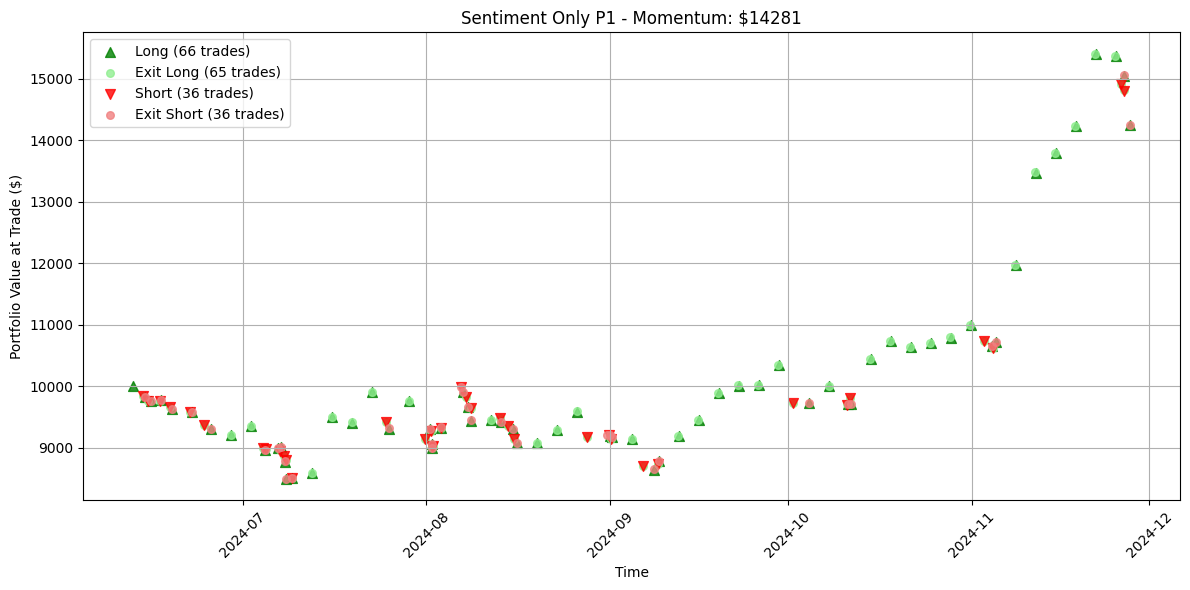


--- Test Period 2 ---
Backtest trades saved to backtest_results/sentiment_only/momentum_backtest_trades-2.csv (201 trades)


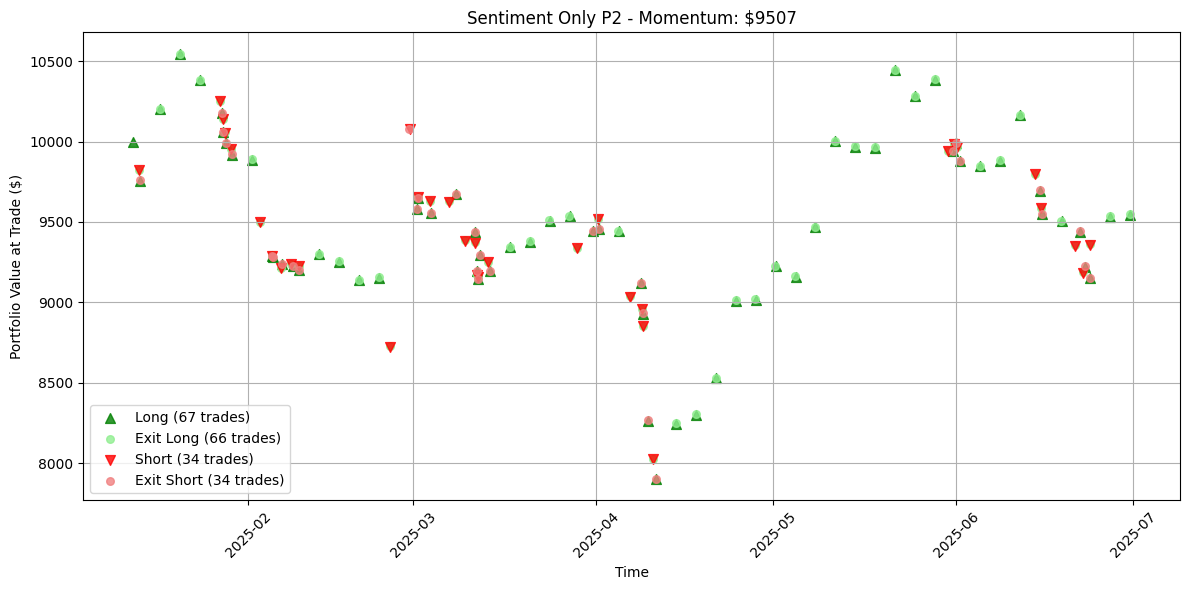

In [9]:
# CV optimize momentum parameters
print("CV optimizing momentum parameters...")
best_lookback, best_hold_hours, best_signal_thresh, best_target_risk = cv_optimize_momentum_parameters(
    train_df, cv_model, seq_length, 'price_change_1h', fixed_transaction_cost_pct, include_target=False
)

print(f"\nOptimized parameters:")
print(f"Lookback: {best_lookback}")
print(f"Hold Hours: {best_hold_hours}")
print(f"Signal Threshold: {best_signal_thresh:.3f}")
print(f"Target Risk: {best_target_risk:.3f}")

print("\n--- Test Period 1 ---")
X_test_p1, _ = create_sequences(val_df_period1, 'price_change_1h', seq_length, include_target=False)
X_test_p1_tensor = prepare_tensor(X_test_p1, device)
test_pred_p1 = make_predictions(model, X_test_p1_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p1 = val_df_period1['close'][seq_length:].values
plot_index_p1 = val_df_period1.index[len(val_df_period1) - len(close_price_p1):]

# Momentum backtest on period 1
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p1,
    predicted_changes=test_pred_p1,
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk,
    threshold=best_signal_thresh,
    initial_capital=10000,
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p1, "Momentum Backtest P1")
save_trades_to_csv(trades_df, 'backtest_results/sentiment_only/momentum_backtest_trades-1.csv')
plot_trades(trades_df, f'Sentiment Only P1 - Momentum: ${final_capital_optimal:.0f}')

print("\n--- Test Period 2 ---")
X_test_p2, _ = create_sequences(val_df_period2, 'price_change_1h', seq_length, include_target=False)
X_test_p2_tensor = prepare_tensor(X_test_p2, device)
test_pred_p2 = make_predictions(model, X_test_p2_tensor, device, df_hourly.columns.get_loc('price_change_1h'))
close_price_p2 = val_df_period2['close'][seq_length:].values
plot_index_p2 = val_df_period2.index[len(val_df_period2) - len(close_price_p2):]

# Momentum backtest on period 2
final_capital_optimal, portfolio_history_optimal, trade_times_opt, trade_values_opt, trade_types_opt = backtest_ts_momentum(
    prices=close_price_p2,
    predicted_changes=test_pred_p2,
    lookback=best_lookback,
    hold_hours=best_hold_hours,
    target_risk_per_trade=best_target_risk,
    threshold=best_signal_thresh,
    initial_capital=10000,
    transaction_cost_pct=fixed_transaction_cost_pct)
trades_df = create_trades_dataframe(trade_times_opt, trade_values_opt, trade_types_opt, plot_index_p2, "Momentum Backtest P2")
save_trades_to_csv(trades_df, 'backtest_results/sentiment_only/momentum_backtest_trades-2.csv')
plot_trades(trades_df, f'Sentiment Only P2 - Momentum: ${final_capital_optimal:.0f}')